# 01 Data Preparation: BRFSS 2023 Diabetes Indicators

**Purpose:** turn the raw 2023 BRFSS survey file into a clean table for exploration and modeling, and record **why** each choice was made.

**Source:** CDC Behavioral Risk Factor Surveillance System (BRFSS), 2023 survey year, read from the `hesscl/quackrfss` dataset on Hugging Face (Parquet format).

**Sections:** 1. Setup and the raw file, 2. Column selection, 3. Raw answer codes, 4. Recoding, 5. Missing data, 6. Target decision, 7. Save, 8. Summary of decisions.

**Output:** `brfss2023_diabetes_clean.csv`, used by `02_EDA`.

## 1. Set up the raw data

In [1]:
# %pip install duckdb pandas    

import duckdb               # lets query the Hugging Face file without downloading all of it
import numpy as np        
import pandas as pd       

URL = "hf://datasets/hesscl/quackrfss/data/BRFSS_2023.parquet"   # the 2023 survey file
con = duckdb.connect()      # open a DuckDB connection

In [2]:
# Every column name and type in the raw file
raw_cols = con.sql(f"DESCRIBE SELECT * FROM read_parquet('{URL}')").df()

# Number of respondents (rows)
n_rows = con.sql(f"SELECT COUNT(*) FROM read_parquet('{URL}')").fetchone()[0]

print("Raw file:", n_rows, "respondents and", len(raw_cols), "columns")
raw_cols["column_name"].head(20).tolist()   # a peek at the first 20 column names

Raw file: 433323 respondents and 477 columns


['YEAR',
 '_STATE',
 '_STATE_lbl',
 'FMONTH',
 'FMONTH_lbl',
 'IDATE',
 'IMONTH',
 'IMONTH_lbl',
 'IDAY',
 'IYEAR',
 'DISPCODE',
 'SEQNO',
 '_PSU',
 'CTELENM1',
 'PVTRESD1',
 'COLGHOUS',
 'COLGHOUS_lbl',
 'STATERE1',
 'CELPHON1',
 'LADULT1']

In [3]:
# BRFSS 2023 variable -> friendly name
COLS = {
    "DIABETE4": "diabetes",        # target
    "_RFHYPE6": "high_bp",
    "_RFCHOL3": "high_chol",
    "_CHOLCH3": "chol_check",
    "_BMI5": "bmi",
    "SMOKE100": "smoker",
    "CVDSTRK3": "stroke",
    "_MICHD": "heart_disease",
    "_TOTINDA": "phys_activity",
    "_RFDRHV8": "heavy_drinker",
    "_HLTHPL1": "any_healthcare",
    "MEDCOST1": "no_doc_cost",
    "GENHLTH": "gen_health",
    "MENTHLTH": "ment_health_days",
    "PHYSHLTH": "phys_health_days",
    "DIFFWALK": "diff_walk",
    "_SEX": "sex",
    "_AGEG5YR": "age_group",
    "EDUCA": "education",
    "INCOME3": "income",
    "_LLCPWT": "weight",           # survey weight
}

# Which of our chosen columns really exist in the 2023 file?
available = set(raw_cols["column_name"])
missing = [c for c in COLS if c not in available]
use = [c for c in COLS if c in available]     # this is the list the loading step needs

print("Chosen:", len(COLS), " Found:", len(use), " Not found:", missing)

Chosen: 21  Found: 21  Not found: []


In [4]:
# Load only the chosen columns from the raw 2023 file
select = ", ".join(f'"{c}"' for c in use)                     
df = con.sql(f"SELECT {select} FROM read_parquet('{URL}')").df()   
df = df.rename(columns=COLS)                                  
print("Loaded:", df.shape)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded: (433323, 21)


The 2023 file has several hundred columns, and we use 21 of them. The fruit and vegetable intake columns (`_FRTLT1A`, `_VEGLT1A`) are common indicators in diabetes studies but were not found in this file, so they are not included. Section 2 explains the rest of the selection.

## 2. Column selection

The raw file has 477 columns, and we keep 21. The selection is based on **domain knowledge, not on a statistical screen**: we kept the established diabetes risk-factor indicators used in the widely used CDC Diabetes Health Indicators dataset (built from the 2015 survey), plus the target and the survey weight. We did not pick columns by how strongly they correlate with diabetes, because that would let the result decide its own inputs.

This section shows how the 477 columns break down, and why the rest were left out.

In [5]:
all_names = raw_cols["column_name"].tolist()          # all 477 column names
chosen = list(COLS)                                   # the 21 we keep

# 1. "_lbl" columns are readable-text copies of coded columns
label_cols = [c for c in all_names if c.endswith("_lbl")]
non_label = [c for c in all_names if not c.endswith("_lbl")]

# 2. Diabetes follow-up questions (only people with diabetes answer these)
keywords = ["DIAB", "INSULIN", "BLDSUGAR", "FEETCHK", "CHKHEMO", "EYEEXAM"]
diabetes_followup = [c for c in non_label
                     if any(k in c.upper() for k in keywords) and c not in chosen]

# 3. Everything else (identifiers, survey design, other topics, optional modules)
other = [c for c in non_label if c not in chosen and c not in diabetes_followup]

print("Total columns:        ", len(all_names))
print("Label copies (_lbl):  ", len(label_cols))
print("Chosen:               ", len(chosen))
print("Diabetes follow-ups:  ", len(diabetes_followup))
print("Everything else:      ", len(other))
print()
print("Diabetes follow-up columns found:", diabetes_followup)

Total columns:         477
Label copies (_lbl):   126
Chosen:                21
Diabetes follow-ups:   9
Everything else:       321

Diabetes follow-up columns found: ['DIABAGE4', 'PDIABTS1', 'PREDIAB2', 'DIABTYPE', 'INSULIN1', 'CHKHEMO3', 'EYEEXAM1', 'DIABEYE1', 'DIABEDU1']


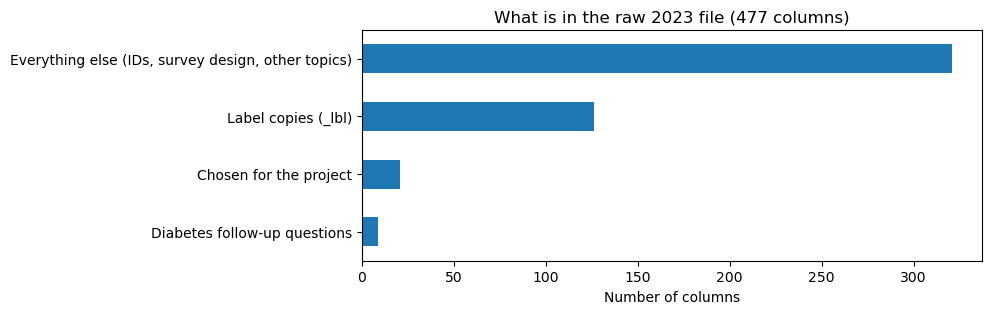

In [6]:
import matplotlib.pyplot as plt

counts = {
    "Label copies (_lbl)": len(label_cols),
    "Diabetes follow-up questions": len(diabetes_followup),
    "Everything else (IDs, survey design, other topics)": len(other),
    "Chosen for the project": len(chosen),
}

pd.Series(counts).sort_values().plot(kind="barh", figsize=(8, 3))
plt.xlabel("Number of columns")
plt.title("What is in the raw 2023 file (477 columns)")
plt.show()

### What we kept and what we left out

**Kept (21 columns)**

| Group | Columns | Reason |
|---|---|---|
| Target | `DIABETE4` | Whether the person was told they have diabetes or prediabetes |
| Heart and metabolic conditions | `_RFHYPE6`, `_RFCHOL3`, `_CHOLCH3`, `_BMI5`, `CVDSTRK3`, `_MICHD` | Established diabetes risk factors |
| Lifestyle | `SMOKE100`, `_TOTINDA`, `_RFDRHV8` | Smoking, physical activity, heavy drinking |
| Health-care access | `_HLTHPL1`, `MEDCOST1` | Coverage and cost barriers |
| Health status | `GENHLTH`, `MENTHLTH`, `PHYSHLTH`, `DIFFWALK` | Self-rated health and mobility |
| Demographics | `_SEX`, `_AGEG5YR`, `EDUCA`, `INCOME3` | Basic background (`INCOME3` is dropped later, see section 5) |
| Survey weight | `_LLCPWT` | Needed for population-level estimates |

**Left out**

| Columns | Reason |
|---|---|
| `_lbl` columns | Readable copies of coded columns, no new information |
| Identifiers and survey administration (`YEAR`, `_STATE`, `FMONTH`, `IDATE`, `SEQNO`, `_PSU`...) | Not health traits, and `YEAR` is the same for every row |
| Diabetes follow-up questions answered only by people with diabetes (`DIABAGE4`, `DIABTYPE`, `INSULIN1`, `CHKHEMO3`, `EYEEXAM1`, `DIABEYE1`, `DIABEDU1`) | Blank for everyone who did not report diabetes, so they would reveal the answer if used as predictors (a data leak). Most are also answered by only about 41% of people with diabetes. |
| Prediabetes-related questions (`PDIABTS1`, `PREDIAB2`) | Asked only of people who did not report diabetes, and only about 45% of them, so they are blank for all people with diabetes and for over half of everyone else. They are also closely tied to the diagnosis we are predicting. |
| Fruit and vegetable intake (`_FRTLT1A`, `_VEGLT1A`) | Not found in the 2023 file |
| Optional-module and state-added questions | Asked only in some states, so mostly empty |
| Other columns not chosen (for example race and ethnicity, state, employment) | Outside the scope of this project, which follows the established 21 indicators. They could be added as an extension. |

**Limitation:** because the selection follows an existing list of indicators, other columns that might relate to diabetes were not tested.

In [7]:
# Load DIABETE4 (the raw target) next to the nine follow-up columns
cols_sql = ", ".join(f'"{c}"' for c in ["DIABETE4"] + diabetes_followup)
check = con.sql(f"SELECT {cols_sql} FROM read_parquet('{URL}')").df()

# For each DIABETE4 group, the % of people who gave any answer to each follow-up column
answered = check.drop(columns="DIABETE4").notna().groupby(check["DIABETE4"]).mean() * 100
answered.round(0)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,DIABAGE4,PDIABTS1,PREDIAB2,DIABTYPE,INSULIN1,CHKHEMO3,EYEEXAM1,DIABEYE1,DIABEDU1
DIABETE4,,,,,,,,,
1.0,100.0,0.0,0.0,41.0,41.0,41.0,41.0,41.0,41.0
2.0,0.0,46.0,46.0,0.0,0.0,0.0,0.0,0.0,0.0
3.0,0.0,44.0,44.0,0.0,0.0,0.0,0.0,0.0,0.0
4.0,0.0,46.0,46.0,0.0,0.0,0.0,0.0,0.0,0.0
7.0,0.0,46.0,45.0,0.0,0.0,0.0,0.0,0.0,0.0
9.0,0.0,39.0,39.0,0.0,0.0,0.0,0.0,0.0,0.0


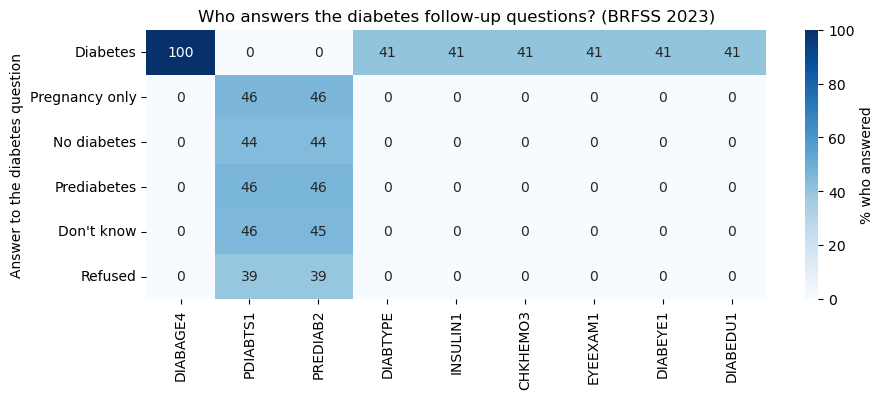

In [8]:
import seaborn as sns

# Readable names for the DIABETE4 codes
names = {1: "Diabetes", 2: "Pregnancy only", 3: "No diabetes",
         4: "Prediabetes", 7: "Don't know", 9: "Refused"}
plot_df = answered.rename(index=names)

plt.figure(figsize=(10, 3.5))
sns.heatmap(plot_df, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% who answered"})
plt.ylabel("Answer to the diabetes question")
plt.title("Who answers the diabetes follow-up questions? (BRFSS 2023)")
plt.show()

**Finding:** the diabetes follow-up questions are asked of different people depending on their answer to the main diabetes question, and the two sets never overlap.

- `DIABAGE4` is answered by 100% of people who reported diabetes and by nobody else. Six more (`DIABTYPE`, `INSULIN1`, `CHKHEMO3`, `EYEEXAM1`, `DIABEYE1`, `DIABEDU1`) are answered by about 41% of people with diabetes and by nobody else.
- `PDIABTS1` and `PREDIAB2` are the reverse: blank for everyone who reported diabetes, and answered by about 39-46% of everyone else.

Because a blank in these columns already tells you the person's diabetes group, using them as predictors would leak the answer. All nine are excluded.

## 3. Raw answer codes

BRFSS stores every answer as a number. Some numbers are real answers, and some mean "don't know", "refused" or "missing". The meaning of a code depends on the column: for example, 9 means "refused" in the education column but is a real answer (9 days) in the mental health days column, and 7 is a real income bracket. That is why the recoding in section 4 is done column by column and not with one blanket rule.

| Columns | Real answers | Not real answers |
|---|---|---|
| `smoker`, `stroke`, `no_doc_cost`, `diff_walk` | 1 = yes, 2 = no | 7 = don't know, 9 = refused |
| `high_bp`, `high_chol`, `heavy_drinker` (CDC-calculated risk flags) | 1 = no, 2 = yes | 9 = don't know, refused or missing |
| `phys_activity`, `any_healthcare` (CDC-calculated) | 1 = yes, 2 = no | 9 = don't know, refused or missing |
| `heart_disease` (CDC-calculated) | 1 = reported, 2 = not reported | none (blank if missing) |
| `chol_check` | 1 = within the past 5 years, 2 = not within 5 years, 3 = never | 9 = don't know, refused or missing |
| `diabetes` (target) | 1 = yes, 2 = yes but only during pregnancy, 3 = no, 4 = prediabetes | 7 = don't know, 9 = refused |
| `gen_health` | 1 = excellent ... 5 = poor | 7 = don't know, 9 = refused |
| `ment_health_days`, `phys_health_days` | 1-30 days, 88 = none | 77 = don't know, 99 = refused |
| `age_group` | 1-13 (five-year bands) | 14 = don't know, refused or missing |
| `education` | 1-6 | 9 = refused |
| `income` | 1-11 (income brackets) | 77 = don't know, 99 = refused |
| `sex` | 1 = male, 2 = female | none |
| `bmi` | BMI multiplied by 100 | blank if missing |


In [9]:
# The codes that are NOT real answers, column by column (from the table above)
special_codes = {
    "diabetes": [7, 9],        "high_bp": [9],           "high_chol": [9],
    "chol_check": [9],         "bmi": [],                "smoker": [7, 9],
    "stroke": [7, 9],          "heart_disease": [],      "phys_activity": [9],
    "heavy_drinker": [9],      "any_healthcare": [9],    "no_doc_cost": [7, 9],
    "gen_health": [7, 9],      "ment_health_days": [77, 99],
    "phys_health_days": [77, 99],  "diff_walk": [7, 9],  "sex": [],
    "age_group": [14],         "education": [9],         "income": [77, 99],
}

rows = []
for col, codes in special_codes.items():
    n_coded = df[col].isin(codes).sum()    # answers coded as don't know / refused / missing
    n_blank = df[col].isna().sum()         # cells that are empty in the raw file
    rows.append({
        "column": col,
        "non_answer_codes": codes,
        "n_coded": n_coded,
        "n_blank": n_blank,
        "% not a real answer": (n_coded + n_blank) / len(df) * 100,
    })

code_summary = pd.DataFrame(rows).set_index("column")
code_summary.sort_values("% not a real answer", ascending=False).round(1)

,non_answer_codes,n_coded,n_blank,% not a real answer
column,,,,
income,"[77, 99]",78548,8075,20.0
high_chol,[9],3273,51811,12.7
bmi,[],0,40535,9.4
heavy_drinker,[9],32825,0,7.6
chol_check,[9],26449,0,6.1
smoker,"[7, 9]",2894,19674,5.2
any_healthcare,[9],18674,0,4.3
diff_walk,"[7, 9]",1704,16146,4.1
phys_health_days,"[77, 99]",10782,3,2.5


## 4. Recoding

Each rule below turns the raw survey codes from section 3 into a usable value. Anything that is not a real answer becomes a missing value (`NaN`), which section 5 deals with.

| Rule | Columns | What it does |
|---|---|---|
| Yes/no flags | `smoker`, `stroke`, `heart_disease`, `phys_activity`, `any_healthcare`, `no_doc_cost`, `diff_walk` | 1 (yes) stays 1 and 2 (no) becomes 0. Codes not in the rule (7, 9) become missing. |
| Risk flags | `high_bp`, `high_chol`, `heavy_drinker` | The CDC codes these as 1 = no and 2 = yes, so the rule flips them to 0 = no and 1 = yes, to match the other flags. |
| Cholesterol check | `chol_check` | Checked within 5 years becomes 1. "Not within 5 years" and "never" both become 0. |
| Sex | `sex` | 1 (male) becomes 0 and 2 (female) becomes 1. |
| Target | `diabetes` | No diabetes (3) and pregnancy-only diabetes (2) become 0, prediabetes (4) becomes 1, diabetes (1) becomes 2. Don't know and refused become missing. |
| BMI | `bmi` | Divided by 100, because the file stores BMI multiplied by 100. |
| Days of poor health | `ment_health_days`, `phys_health_days` | 88 ("none") becomes 0. 77 and 99 become missing. |
| Scales | `gen_health`, `education`, `age_group` | The "don't know" and "refused" codes (7 and 9, 9, and 14) become missing. |
| Income | `income` | 77 and 99 become missing (this column is dropped in section 5). |

**Note:** the yes/no rules use a mapping, and a mapping turns any value it doesn't list into missing. That is how the 7s and 9s disappear, without a separate line for them.

In [10]:
yes_no = {1: 1, 2: 0}      # 1 = yes, 2 = no (7 and 9 are not listed, so they become missing)
risk_flag = {1: 0, 2: 1}   # CDC "_RF" columns: 1 = no, 2 = yes, so we flip them

# Yes/no flags
for c in ["smoker", "stroke", "heart_disease", "phys_activity",
          "any_healthcare", "no_doc_cost", "diff_walk"]:
    df[c] = df[c].map(yes_no)

# Risk flags
for c in ["high_bp", "high_chol", "heavy_drinker"]:
    df[c] = df[c].map(risk_flag)

df["chol_check"] = df["chol_check"].map({1: 1, 2: 0, 3: 0})   # 9 becomes missing
df["sex"] = df["sex"].map({1: 0, 2: 1})                       # 0 = male, 1 = female

# Target: 0 = no diabetes (incl. pregnancy only), 1 = prediabetes, 2 = diabetes
df["diabetes"] = df["diabetes"].map({3: 0, 2: 0, 4: 1, 1: 2})

df["bmi"] = df["bmi"] / 100

# Days of poor health: 88 = none, 77 and 99 = not real answers
for c in ["ment_health_days", "phys_health_days"]:
    df[c] = df[c].replace({88: 0, 77: np.nan, 99: np.nan})

# Scales: remove the "don't know" and "refused" codes
df["gen_health"] = df["gen_health"].replace({7: np.nan, 9: np.nan})
df["education"] = df["education"].replace({9: np.nan})
df["income"] = df["income"].replace({77: np.nan, 99: np.nan})
df["age_group"] = df["age_group"].replace({14: np.nan})

In [11]:
# Missing values after recoding vs the non-answers counted in section 3
after = df.isna().sum()
expected = code_summary["n_coded"] + code_summary["n_blank"]

check = pd.DataFrame({
    "expected_missing": expected,
    "missing_after": after[expected.index],
})
check["match"] = check["expected_missing"] == check["missing_after"]

print("All columns match:", check["match"].all())
check[~check["match"]]     

All columns match: True


,expected_missing,missing_after,match
column,,,


In [12]:
flag_cols = ["high_bp", "high_chol", "chol_check", "smoker", "stroke", "heart_disease",
             "phys_activity", "heavy_drinker", "any_healthcare", "no_doc_cost",
             "diff_walk", "sex"]

for c in flag_cols:
    print(c, sorted(df[c].dropna().unique()))      # the values that remain, ignoring missing
print("diabetes", sorted(df["diabetes"].dropna().unique()))
print("bmi range:", df["bmi"].min(), "to", df["bmi"].max())

high_bp [0.0, 1.0]
high_chol [0.0, 1.0]
chol_check [0.0, 1.0]
smoker [0.0, 1.0]
stroke [0.0, 1.0]
heart_disease [0.0, 1.0]
phys_activity [0.0, 1.0]
heavy_drinker [0.0, 1.0]
any_healthcare [0.0, 1.0]
no_doc_cost [0.0, 1.0]
diff_walk [0.0, 1.0]
sex [0, 1]
diabetes [0.0, 1.0, 2.0]
bmi range: 12.020000457763672 to 99.83999633789062


In [13]:
print("BMI above 50:", (df["bmi"] > 50).sum())
print("BMI above 60:", (df["bmi"] > 60).sum())

BMI above 50: 3655
BMI above 60: 792


## 5. Missing data

After recoding, every "don't know", "refused" and blank answer is a missing value. This section measures the gaps, shows what each way of handling them costs, and checks who we lose.

**Approach:** keep only respondents with a complete set of answers (a "complete-case" analysis). It is simple and every remaining row has real values. The cost is fewer people, and possibly a different mix of people, which the checks below look at.

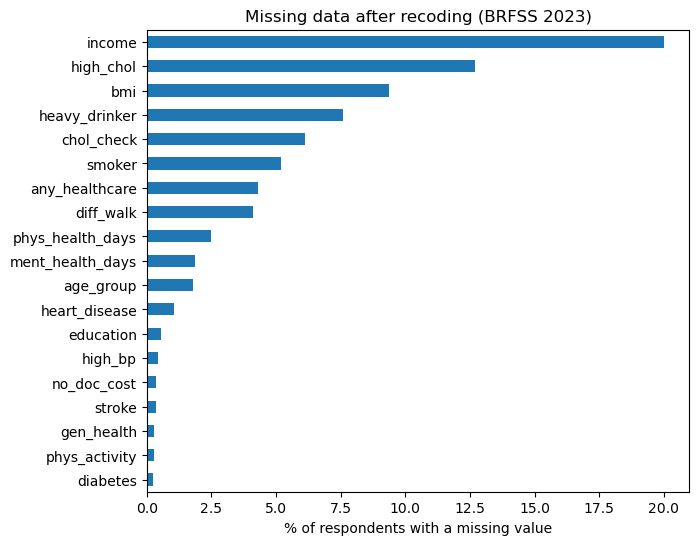

In [14]:
import matplotlib.pyplot as plt   

miss_pct = df.isna().mean() * 100                       # % missing per column
miss_pct = miss_pct[miss_pct > 0].sort_values()         # keep columns with gaps, smallest first

miss_pct.plot(kind="barh", figsize=(7, 6))
plt.xlabel("% of respondents with a missing value")
plt.title("Missing data after recoding (BRFSS 2023)")
plt.show()

In [15]:
base = df.dropna(subset=["diabetes"])       # people with a known diabetes answer

scenarios = {
    "Start (all respondents)": df,
    "Drop people with no diabetes answer": base,
    "Keep only complete rows (all columns)": base.dropna(),
    "Drop income, then keep complete rows": base.drop(columns="income").dropna(),
    "Also drop high_chol": base.drop(columns=["income", "high_chol"]).dropna(),
    "Also drop high_chol and bmi": base.drop(columns=["income", "high_chol", "bmi"]).dropna(),
}

retention = pd.DataFrame({"people_kept": {k: len(v) for k, v in scenarios.items()}})
retention["% of all respondents"] = retention["people_kept"] / len(df) * 100
retention.round(1)

,people_kept,% of all respondents
Also drop high_chol,321267,74.1
Also drop high_chol and bmi,338512,78.1
"Drop income, then keep complete rows",300760,69.4
Drop people with no diabetes answer,432339,99.8
Keep only complete rows (all columns),261589,60.4
Start (all respondents),433323,100.0


In [16]:
data = base.drop(columns="income")                 # the version we plan to keep
complete = data.notna().all(axis=1)                # True if the person has no missing value

who = pd.DataFrame({
    "people": data.groupby(complete).size(),
    "% prediabetes or diabetes": data.groupby(complete)["diabetes"].apply(lambda s: (s >= 1).mean() * 100),
    "average age group": data.groupby(complete)["age_group"].mean(),
    "% female": data.groupby(complete)["sex"].mean() * 100,
})
who.index = ["dropped (missing something)", "kept (complete)"]
who.round(1)

,people,% prediabetes or diabetes,average age group,% female
dropped (missing something),131579,13.9,6.8,54.0
kept (complete),300760,17.3,8.1,52.6


In [17]:
df = df.dropna(subset=["diabetes"]).drop(columns="income").dropna().reset_index(drop=True)
print(df.shape)

(300760, 20)


**Decision:** drop the `income` column and keep only complete rows, leaving **300,760 respondents (69.4% of all 433,323)**.

- `income` has the most missing answers (20.0%). Dropping it recovers about 39,000 people, more than any other column.
- `high_chol` (12.7%) and `bmi` (9.4%) would recover another 20,000 and 17,000 people, but both are well-established diabetes risk factors, so we keep them.
- **Who we lose:** the 131,579 dropped respondents are younger on average (average age band 6.8 vs 8.1) and less likely to have prediabetes or diabetes (13.9% vs 17.3%); the share of women is similar (54.0% vs 52.6%). The cleaned data therefore over-represents older people, and the 17.3% rate describes respondents with complete answers, not all respondents (about 16.3% among everyone with a known diabetes answer).
- **Cost of dropping `income`:** it is one of the few socioeconomic variables available, so the analysis cannot look at income.
- **Extreme BMI values:** 3,655 respondents report a BMI above 50 and 792 above 60 (maximum 99.8). They were kept as reported.

## 6. Target decision: one group or two?

**The question:** does prediabetes look more like diabetes, more like no diabetes, or somewhere in between?

,people,% of people
No diabetes,248707,82.7
Prediabetes,7688,2.6
Diabetes,44365,14.8


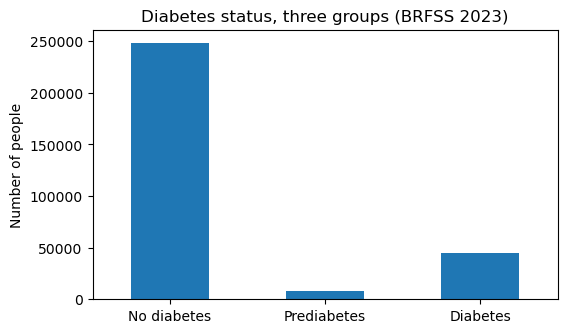

In [18]:
names = {0: "No diabetes", 1: "Prediabetes", 2: "Diabetes"}

counts = df["diabetes"].value_counts().sort_index()
three_class = pd.DataFrame({
    "people": counts,
    "% of people": (counts / counts.sum() * 100).round(1),
})
three_class.index = three_class.index.map(names)
display(three_class)

three_class["people"].plot(kind="bar", figsize=(6, 3.5), rot=0)
plt.ylabel("Number of people")
plt.title("Diabetes status, three groups (BRFSS 2023)")
plt.show()

In [19]:
traits = ["high_bp", "high_chol", "heart_disease", "diff_walk",
          "phys_activity", "bmi", "age_group", "gen_health"]

# Average of each trait in the three groups
three = df.groupby("diabetes")[traits].mean().T
three.columns = ["no_diabetes", "prediabetes", "diabetes"]

# Where prediabetes sits between the other two:
# 0 = same as no diabetes, 1 = same as diabetes, 0.5 = halfway between
three["prediabetes_position"] = (three["prediabetes"] - three["no_diabetes"]) / (three["diabetes"] - three["no_diabetes"])
three.round(2)

,no_diabetes,prediabetes,diabetes,prediabetes_position
high_bp,0.38,0.59,0.74,0.59
high_chol,0.38,0.59,0.65,0.80
heart_disease,0.07,0.12,0.21,0.39
diff_walk,0.12,0.25,0.34,0.60
phys_activity,0.80,0.70,0.62,0.54
bmi,28.10,31.17,31.72,0.85
age_group,7.83,8.86,9.63,0.57
gen_health,2.45,2.96,3.24,0.64


**Decision:** merge prediabetes and diabetes into one target, `diabetes_binary` (0 = none, 1 = prediabetes or diabetes).

- Prediabetes is only 2.6% of respondents (7,688 people).
- On the eight traits compared, prediabetes sits clearly above "no diabetes" on every one and, on average, about 60% of the way towards diabetes. It is closest to diabetes on BMI (0.85) and high cholesterol (0.80), about halfway on blood pressure, age, activity and walking difficulty, and closer to "no diabetes" on heart disease (0.39).
- The merged target is "has raised blood sugar of either kind". It answers a broader question than "has diagnosed diabetes".
- **Limitations:** merging hides differences between the two groups, and the prediabetes averages rest on a small group. Part of the differences reflects age.
- The merged target is still imbalanced (82.7% / 17.3%), so accuracy alone will be misleading in modeling.

In [20]:
if "diabetes" in df.columns:                                    # only merge if the 3-group column is still there
    df["diabetes_binary"] = (df["diabetes"] >= 1).astype(int)   # 0 = none, 1 = prediabetes or diabetes
    df = df.drop(columns=["diabetes"])                          # remove the three-group column

print(df["diabetes_binary"].value_counts())
print(df["diabetes_binary"].value_counts(normalize=True).round(3))

0    248707
1     52053
Name: diabetes_binary, dtype: int64
0    0.827
1    0.173
Name: diabetes_binary, dtype: float64


## 7. Save

One file is saved for the next notebooks:

- `brfss2023_diabetes_clean.csv` is the cleaned data with the merged target (`diabetes_binary`), used by `02_EDA` and `03_modeling`.

The three-group version of the target is not saved. Section 6 shows why prediabetes and diabetes were merged, and the notebook can be re-run if a three-class analysis is wanted later.

In [21]:
print("Shape:", df.shape)                          # (people, columns)
print("Missing values:", df.isna().sum().sum())    # should be 0
df.dtypes.value_counts()                           # how many columns of each type

Shape: (300760, 20)
Missing values: 0


float64    11
float32     7
int64       1
int32       1
dtype: int64

In [22]:
df.to_csv("brfss2023_diabetes_clean.csv", index=False)   

## 8. Summary of decisions

| # | Decision | Reason | Effect |
|---|---|---|---|
| 1 | Use the 2023 survey year only | Working year for the project; other years were not tested | 433,323 respondents, 477 columns |
| 2 | Keep 21 of 477 columns | Established diabetes risk factors from a known list (domain knowledge, not a statistical screen) | 21 columns kept |
| 3 | Exclude the 9 diabetes follow-up questions | Blank for people outside one diabetes group, so they would reveal the answer (data leak) | 9 columns left out |
| 4 | Fruit and vegetable intake not included | Not found in the 2023 file | 2 common indicators missing |
| 5 | Turn "don't know", "refused" and missing codes into missing values | These are not real answers (7, 9, 77, 99, 14), and 88 in the health-days columns means 0 days | Gaps range from 0.2% to 20.0% per column |
| 6 | Count pregnancy-only diabetes as "no diabetes" | The target is about diabetes outside pregnancy | 3,253 respondents (before other drops) |
| 7 | Code "never checked" and "not within 5 years" both as 0 in `chol_check` | Both mean no recent cholesterol check | 38,252 respondents (before other drops) |
| 8 | Drop people with no diabetes answer | The target must be known | 984 respondents (0.2%) |
| 9 | Drop the `income` column | Most missing answers (20.0%), and dropping it recovers the most people | 39,171 more respondents kept |
| 10 | Keep `high_chol` (12.7% missing) and `bmi` (9.4% missing) | Established risk factors, worth the loss of 20,507 and 17,245 respondents | 2 columns kept despite gaps |
| 11 | Keep only complete rows | Simple, and every row has real values | 300,760 respondents kept (69.4%) |
| 12 | Keep extreme BMI values as reported | Removing them is a judgment call that affects few people | 3,655 above BMI 50, 792 above 60 |
| 13 | Merge prediabetes and diabetes into one target | Prediabetes is small (7,688 people, 2.6%) and sits about 60% of the way towards diabetes on the traits checked | Target is 82.7% / 17.3% |
| 14 | Save one cleaned file | Used by `02_EDA` | `brfss2023_diabetes_clean.csv`, 300,760 rows, 20 columns |
